# Session 9 lecture: Sampling, uncertainty and experiments

<p class="lead">
Almost every number an analyst reports comes from a sample, and a different sample would have given a slightly different number. This lecture shows how big that wobble is, how to put an honest range around an estimate, and how to read an A/B test without fooling yourself or your manager.
</p>

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Aayush181509/AnalyticsLecture/blob/main/notebooks/09_sampling_and_experiments_lecture.ipynb)

Open this notebook in Google Colab with the button above, then run each cell from top to bottom with **Shift + Enter**. Save your own copy with **File → Save a copy in Drive**.

---

## Recap quiz

Before we start, answer these questions on the [Session 8 lecture](08_correlation_and_regression_lecture.md). Write short answers; we discuss them together.

1. The correlation between weekly advertising spend and weekly sales is strongly positive. Say what this tells you, and one thing it does **not** tell you.
2. A regression of revenue on advertising spend has a slope of 4. Say in plain words what the slope means, with units.
3. Ice-cream sales and sunburn cases rise and fall together. Why might that be, and what is the general lesson?
4. A correlation is close to zero. Does that prove the two measures are unrelated? Give a reason.
5. Name one thing you should always do **before** calculating a correlation or fitting a line.

---

## What you will be able to explain

1. The difference between a **population** and a **sample**, and why every sample has **sampling error**.
2. What a **sampling distribution** is, using simulation rather than formulas.
3. What the **standard error** measures, and why it shrinks with the **square root** of the sample size.
4. How to build a **confidence interval**: by the **bootstrap** first, then by the formula *estimate ± 1.96 × standard error*.
5. What "**95% confidence**" does and does not mean.
6. How an **A/B test** works: randomisation, control and treatment, conversion rate and **lift**.
7. How to get a **confidence interval** for a lift and a **p-value** from a **permutation test**, and how to explain both in plain words.
8. Why **practical** and **statistical** significance differ, and why **peeking** and **slicing** produce false winners.

This lecture builds on [How statistics can mislead](../foundations/misleading-statistics.md). In the **Lab** you put a range around an average order value and analyse a checkout-page test yourself.

> **How to use the questions in this notebook**
>
> **Predict, then reveal** boxes ask you to guess before running the next cell. Write your guess down first. **Check your understanding** boxes are short questions to answer in your own words.

Run the two setup cells first: one for the Superstore orders and one for the synthetic marketing data. Every simulation uses **numpy** with a fixed **seed**, so your "random" numbers match everyone else's.

In [1]:
# Course data setup. Run this cell first; you do not need to understand it yet.
# It downloads the Superstore sample from Tableau's website, checks it is the
# exact version this course was written for, and prepares the order-lines table.
import hashlib
import os
import urllib.request

import matplotlib.pyplot as plt
import pandas as pd

SOURCE_URL = "https://public.tableau.com/app/sample-data/sample_-_superstore.xls"
EXPECTED_SHA256 = "5045ed4fec49cae2cc0dfc5ab0d204ba09efa767fe00c996822499e8cc42fbbd"
SOURCE_FILE = os.environ.get("COURSE_XLS_PATH", "sample_-_superstore.xls")

try:
    import xlrd  # noqa: F401  (needed to read .xls files)
except ImportError:
    import subprocess
    import sys

    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "xlrd"])

if not os.path.exists(SOURCE_FILE):
    urllib.request.urlretrieve(SOURCE_URL, SOURCE_FILE)

with open(SOURCE_FILE, "rb") as f:
    digest = hashlib.sha256(f.read()).hexdigest()
if digest != EXPECTED_SHA256:
    print("WARNING: Tableau has changed this sample file since the course was written.")
    print("Your numbers will differ from the lesson. Ask your facilitator for the course copy.")


def load_orders():
    """Return one row per order line, orders placed 2023-01-01 to 2025-12-31."""
    raw = pd.read_excel(SOURCE_FILE, sheet_name="Orders")
    returns = pd.read_excel(SOURCE_FILE, sheet_name="Returns")

    # Orders with more than one Customer ID (a known data issue), found before filtering.
    ids_per_order = raw.groupby("Order ID")["Customer ID"].nunique()
    conflict_orders = set(ids_per_order[ids_per_order > 1].index)

    in_scope = (raw["Order Date"] >= "2023-01-01") & (raw["Order Date"] < "2026-01-01")
    df = raw.loc[in_scope].copy()

    df = df.rename(columns={
        "Row ID": "row_id", "Order ID": "order_id", "Order Date": "order_date",
        "Ship Date": "ship_date", "Ship Mode": "ship_mode", "Customer ID": "customer_id",
        "Segment": "segment", "Country/Region": "country_region", "Region": "region",
        "Category": "category", "Sub-Category": "sub_category", "Product ID": "product_id",
        "Product Name": "product_name", "Sales": "sales", "Quantity": "quantity",
        "Discount": "discount", "Profit": "profit",
    })
    df["returned_order_flag"] = df["order_id"].isin(set(returns["Order ID"])).astype(int)
    df["customer_order_conflict"] = df["order_id"].isin(conflict_orders).astype(int)
    df["customer_analysis_eligible"] = 1 - df["customer_order_conflict"]
    df["order_to_ship_days"] = (df["ship_date"] - df["order_date"]).dt.days
    df["order_month"] = df["order_date"].dt.to_period("M").dt.to_timestamp()

    columns = [
        "row_id", "order_id", "order_date", "ship_date", "ship_mode", "customer_id",
        "segment", "country_region", "region", "category", "sub_category", "product_id",
        "product_name", "sales", "quantity", "discount", "profit", "returned_order_flag",
        "customer_analysis_eligible", "customer_order_conflict", "order_to_ship_days",
        "order_month",
    ]
    return df[columns].sort_values("row_id").reset_index(drop=True)


pd.set_option("display.float_format", "{:,.2f}".format)
plt.rcParams.update({
    "figure.figsize": (8, 4),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#e6e5e1",
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a"]),
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
})
print("Setup complete.")

Setup complete.


In [2]:
# Marketing data setup (synthetic). Run this cell first.
# Downloads the course's synthetic marketing data from GitHub and checks it is the exact version this course uses.
import hashlib
import io
import os
import urllib.request

import pandas as pd

MARKETING_URL = "https://raw.githubusercontent.com/Aayush181509/AnalyticsLecture/main/data/synthetic/marketing-v1/"
MARKETING_SHA256 = {
    "marketing_daily.csv": "1cbfc8e1c91ae72d18364b2d13bdf6db513c4aec28c339ef8b91f87a60dc0a07",
    "ab_test.csv": "41a3662997111b66d7ab1eb899f4b32e26bd64c66284ce881db6b8a7300ad47f",
}
MARKETING_DIR = os.environ.get("COURSE_MARKETING_DIR", "")


def load_marketing(name):
    """Load one marketing-v1 file: 'marketing_daily.csv' or 'ab_test.csv'."""
    if MARKETING_DIR:
        with open(os.path.join(MARKETING_DIR, name), "rb") as f:
            data = f.read()
    else:
        data = urllib.request.urlopen(MARKETING_URL + name).read()
    if hashlib.sha256(data).hexdigest() != MARKETING_SHA256[name]:
        print("WARNING: this file differs from the course version. Ask your facilitator.")
    return pd.read_csv(io.BytesIO(data), parse_dates=["date"])


print("Marketing setup complete.")

Marketing setup complete.


In [3]:
import math

import numpy as np

df = load_orders()
orders = df.groupby("order_id")["sales"].sum()
print("Order lines:", len(df), "| orders:", len(orders))

Order lines: 6815 | orders: 3388


---

## Part 1: Population, sample and sampling error

The Superstore table has one row per **order line**. Average order value (**AOV**) is a measure of **orders**, so the cell above added up the lines of each order first. Averaging lines would give the average *line* value, a different and smaller number.

For this lecture we play a game. We pretend the Superstore orders from 2023 to 2025 are the **whole population**: every order the company took. Then we can compare what a sample tells us with the true answer, something real life never lets you do.

| Term | Meaning | In our example |
|---|---|---|
| **Population** | Everything you want to know about | All Superstore orders, 2023–2025 |
| **Parameter** | A number describing the population, usually unknown | The true AOV |
| **Sample** | The part you actually observe | 50 orders picked at random |
| **Statistic** | The same number calculated on the sample | The sample's AOV |
| **Sampling error** | Statistic minus parameter: the luck of the draw | Sample AOV − true AOV |

In [4]:
values = orders.to_numpy()
true_mean = values.mean()
print("Population:", len(values), "orders")
print("True AOV:", f"{true_mean:,.2f} source monetary units")

Population: 3388 orders
True AOV: 466.64 source monetary units


> **Predict, then reveal**
>
> We draw three random samples of 50 orders each. Will the three sample AOVs be the same? Will any of them equal the true AOV exactly?

In [5]:
rng = np.random.default_rng(seed=9)
for i in range(3):
    sample = rng.choice(values, size=50, replace=False)
    error = sample.mean() - true_mean
    print(f"Sample {i + 1}: AOV {sample.mean():,.2f} | sampling error {error:+,.2f}")

Sample 1: AOV 350.71 | sampling error -115.92
Sample 2: AOV 568.28 | sampling error +101.64
Sample 3: AOV 238.47 | sampling error -228.17


Read the output above. Each sample gives a different AOV, and none hits the true value exactly. That is **sampling error**. It is not a mistake anyone made: it is the natural wobble of looking at part of the data. The question is never "is there sampling error?" but "**how big** is it likely to be?"

> **Check your understanding 1**
>
> A shop surveys 200 of its 20,000 loyalty-card customers and finds that 34% would use a new delivery option. Name the population, the sample, the statistic and the parameter. Would a second survey of 200 different customers give exactly 34%?

---

## Part 2: The sampling distribution, by simulation

One sample gives one AOV. If we could repeat the sampling many times, we would get a whole **distribution of sample AOVs**: the **sampling distribution**. It shows how far a single sample's answer can land from the truth.

We cannot do this in real life (you get one sample), but with our pretend population we can simulate it: draw 2,000 samples of 100 orders and keep each sample's AOV.

> **Predict, then reveal**
>
> Order values are very skewed: most orders are small and a few are huge. Will the 2,000 sample AOVs be skewed in the same way, or will they look different?

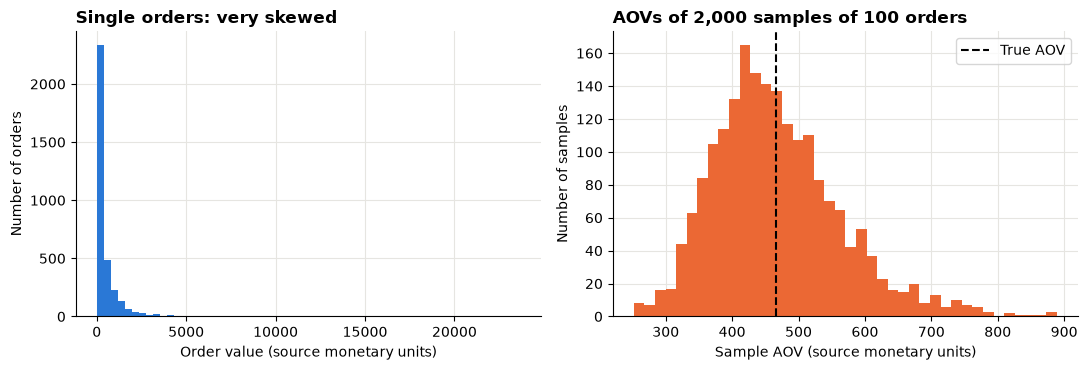

Middle 95% of sample AOVs: 318 to 702
Spread (standard deviation) of sample AOVs: 96.3


In [6]:
n = 100
sample_means = np.array([rng.choice(values, size=n, replace=False).mean() for _ in range(2000)])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
ax1.hist(values, bins=60)
ax1.set_title("Single orders: very skewed")
ax1.set_xlabel("Order value (source monetary units)")
ax1.set_ylabel("Number of orders")
ax2.hist(sample_means, bins=40, color="#eb6834")
ax2.axvline(true_mean, color="black", linestyle="--", label="True AOV")
ax2.set_title(f"AOVs of 2,000 samples of {n} orders")
ax2.set_xlabel("Sample AOV (source monetary units)")
ax2.set_ylabel("Number of samples")
ax2.legend()
fig.tight_layout()
plt.show()

low, high = np.percentile(sample_means, [2.5, 97.5])
print(f"Middle 95% of sample AOVs: {low:,.0f} to {high:,.0f}")
print(f"Spread (standard deviation) of sample AOVs: {sample_means.std():,.1f}")

Three things to notice in the charts and output above:

1. The sample AOVs are **centred on the true AOV**: random samples are right on average.
2. They are **far less spread out** than single orders: averaging 100 orders cancels out much of the luck.
3. Their shape is much closer to a symmetric **bell curve** than the orders themselves. Averages of reasonably large random samples tend towards this shape, whatever the data look like. Statisticians call this the *central limit theorem*; you only need the idea.

> **Check your understanding 2**
>
> Your colleague says: "The sampling distribution is the histogram of my data." What is the difference between the distribution of the data and the sampling distribution of the AOV?

---

## Part 3: Standard error, and why it shrinks with √n

The spread of the sampling distribution has a name: the **standard error (SE)**. It is the typical size of the sampling error. A small SE means one sample's answer is probably close to the truth.

> **Predict, then reveal**
>
> If you make the sample **four times bigger**, does the standard error become four times smaller, twice as small, or stay the same?

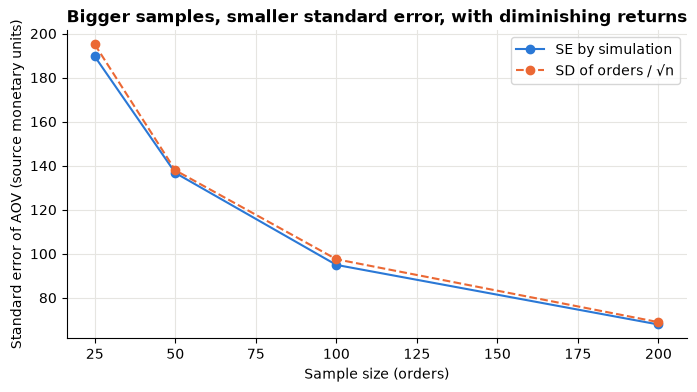

,SE by simulation,SD of orders / √n
sample size,,
25,189.60,195.00
50,136.70,137.90
100,95.00,97.50
200,67.90,69.00


In [7]:
rows = []
for size in [25, 50, 100, 200]:
    means = np.array([rng.choice(values, size=size, replace=False).mean() for _ in range(2000)])
    rows.append({"sample size": size,
                 "SE by simulation": means.std(),
                 "SD of orders / √n": values.std() / math.sqrt(size)})
se_table = pd.DataFrame(rows).set_index("sample size")

ax = se_table.plot(marker="o", style=["-", "--"])
ax.set_title("Bigger samples, smaller standard error, with diminishing returns")
ax.set_xlabel("Sample size (orders)")
ax.set_ylabel("Standard error of AOV (source monetary units)")
plt.show()
se_table.round(1)

The two columns in the table above almost agree. The simulated SE follows a simple rule:

*standard error of a mean = standard deviation of the data ÷ √(sample size)*

Because of the square root, **four times the data halves the SE**. Going from 25 to 100 orders helps a lot; going from 1,000 to 4,000 costs four times as much for the same halving. That is why "just collect more data" has diminishing returns.

In real work you have one sample, so you use **the sample's** standard deviation in the formula. That is what the next part does.

> **Check your understanding 3**
>
> A survey of 400 customers gives an SE of 2 points. Roughly how many customers would you need for an SE of 1 point? Is it worth it if each response costs money?

---

## Part 4: Confidence intervals, bootstrap first

Now the real situation: you have **one** sample of 200 orders and no access to the population. You want a range of plausible values for the true AOV: a **confidence interval (CI)**.

The **bootstrap** gets one by simulation, using only the sample:

1. Treat your sample as a stand-in for the population.
2. Draw a new sample of the same size **from your sample, with replacement** (some orders appear twice, some not at all).
3. Compute its AOV. Repeat thousands of times.
4. The middle 95% of those AOVs (the 2.5th to the 97.5th percentile) is the **bootstrap 95% percentile interval**.

> **Predict, then reveal**
>
> The bootstrap never sees a single order outside your sample. Do you expect its interval to contain the true AOV?

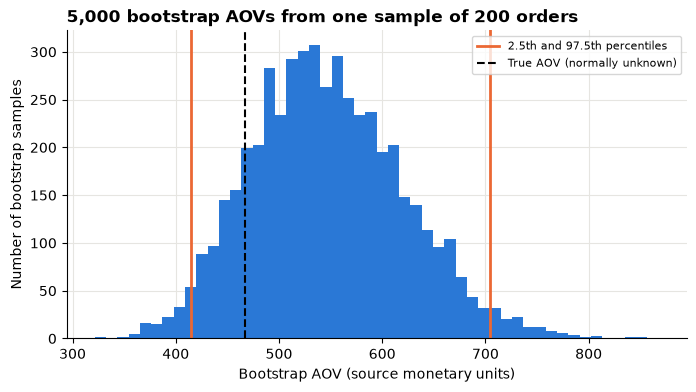

Sample AOV: 546.47
Bootstrap 95% CI: 414.72 to 704.65


In [8]:
my_sample = rng.choice(values, size=200, replace=False)

boot_means = np.array([rng.choice(my_sample, size=len(my_sample), replace=True).mean()
                       for _ in range(5000)])
boot_low, boot_high = np.percentile(boot_means, [2.5, 97.5])

ax = plt.gca()
ax.hist(boot_means, bins=50)
ax.axvline(boot_low, color="#eb6834", linewidth=2, label="2.5th and 97.5th percentiles")
ax.axvline(boot_high, color="#eb6834", linewidth=2)
ax.axvline(true_mean, color="black", linestyle="--", label="True AOV (normally unknown)")
ax.set_title("5,000 bootstrap AOVs from one sample of 200 orders")
ax.set_xlabel("Bootstrap AOV (source monetary units)")
ax.set_ylabel("Number of bootstrap samples")
ax.legend(fontsize=8)
plt.show()

print(f"Sample AOV: {my_sample.mean():,.2f}")
print(f"Bootstrap 95% CI: {boot_low:,.2f} to {boot_high:,.2f}")

The bootstrap works because the spread of AOVs *within your sample's resamples* imitates the spread you would see across real samples. It needs no formula, and it works for medians, ratios and differences just as well as for means.

### The formula interval

For a mean there is also a shortcut. In a bell-shaped sampling distribution, about 95% of values lie within **1.96 standard errors** of the centre, so:

*95% CI = sample mean ± 1.96 × SE, with SE = sample standard deviation ÷ √n*

(`ddof=1` below tells numpy to use the sample standard deviation, which divides by *n − 1*.)

In [9]:
se = my_sample.std(ddof=1) / math.sqrt(len(my_sample))
formula_low = my_sample.mean() - 1.96 * se
formula_high = my_sample.mean() + 1.96 * se

pd.DataFrame({
    "low": [boot_low, formula_low],
    "high": [boot_high, formula_high],
    "contains true AOV": [boot_low <= true_mean <= boot_high, formula_low <= true_mean <= formula_high],
}, index=["Bootstrap percentile", "Formula: mean ± 1.96 × SE"])

,low,high,contains true AOV
Bootstrap percentile,414.72,704.65,True
Formula: mean ± 1.96 × SE,396.95,695.98,True


The two intervals in the table above are close. For large samples they **agree**, because the bootstrap distribution is then close to the bell curve the formula assumes. They differ more when samples are small or the data are very skewed; then the bootstrap shows the lopsidedness and the formula does not.

> **Check your understanding 4**
>
> Write one sentence for a manager that reports the AOV from this sample with its 95% interval. Use the words "between" and "orders", and avoid the word "probability".

---

## Part 5: What "95% confidence" means

A 95% interval does **not** mean "there is a 95% chance the true AOV is in *this* interval". The true AOV is fixed; *this* interval either contains it or not. The 95% describes the **method**: if you repeated the whole process many times, about 95% of the intervals would contain the true value.

We can check that, because we know the true AOV.

> **Predict, then reveal**
>
> We draw 100 samples of 200 orders and build a formula interval from each. How many of the 100 intervals will contain the true AOV?

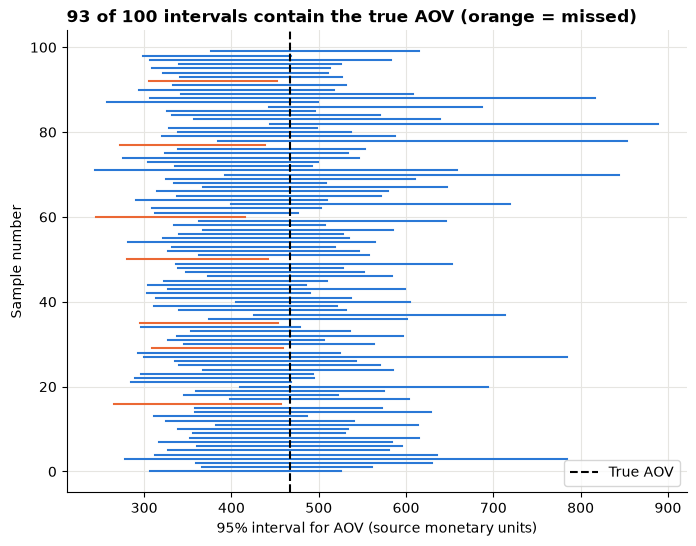

In [10]:
def formula_ci(sample):
    se = sample.std(ddof=1) / math.sqrt(len(sample))
    return sample.mean() - 1.96 * se, sample.mean() + 1.96 * se


intervals = np.array([formula_ci(rng.choice(values, size=200, replace=False)) for _ in range(100)])
covers = (intervals[:, 0] <= true_mean) & (true_mean <= intervals[:, 1])

fig, ax = plt.subplots(figsize=(8, 6))
for i, (low, high) in enumerate(intervals):
    ax.plot([low, high], [i, i], color="#2a78d6" if covers[i] else "#eb6834", linewidth=1.5)
ax.axvline(true_mean, color="black", linestyle="--", label="True AOV")
ax.set_title(f"{covers.sum()} of 100 intervals contain the true AOV (orange = missed)")
ax.set_xlabel("95% interval for AOV (source monetary units)")
ax.set_ylabel("Sample number")
ax.legend(loc="lower right")
plt.show()

Most lines cross the dashed true value; a few (orange) miss it, and from inside one sample you cannot tell which kind you have. That is the honest meaning of 95%.

With many more repetitions we can measure how often the method succeeds for different sample sizes:

In [11]:
rows = []
for size in [30, 100, 200]:
    hits = 0
    for _ in range(2000):
        low, high = formula_ci(rng.choice(values, size=size, replace=False))
        hits += low <= true_mean <= high
    rows.append({"sample size": size, "share of intervals containing true AOV": hits / 2000})
coverage = pd.DataFrame(rows).set_index("sample size")
coverage.map("{:.1%}".format)

,share of intervals containing true AOV
sample size,
30,84.0%
100,89.1%
200,92.5%


> **Very skewed data need bigger samples**
>
> Read the table above. Superstore order values are extremely skewed (a few orders are huge), so with small samples the formula interval is a little too narrow and covers the true AOV **less often than 95%**. The bootstrap percentile interval has the same weakness. Coverage improves as the sample grows. With skewed money data, prefer large samples, and consider also reporting the median.

| Correct reading | Wrong reading |
|---|---|
| "We are 95% confident the true AOV is between *a* and *b*": the method captures the truth 95% of the time | "There is a 95% probability the true AOV is in this interval" |
| A wider interval means **less precision** | A wider interval means the AOV is **higher** or "more variable orders" only |
| The interval is about the **average**, not individual orders | "95% of orders are between *a* and *b*" |

> **Check your understanding 5**
>
> A report says "95% of our customers spend between 410 and 520." The number came from a 95% confidence interval for the mean. What is wrong with the sentence? Rewrite it.

---

## Part 6: Experiments and why we randomise

The marketing team tested a **new checkout page**. Comparing visitors who happened to see a new page with those who did not is risky: if the new page were shown mainly to returning desktop customers, it would look good even if it did nothing.

An **A/B test** solves this with **randomisation**:

| Idea | Meaning |
|---|---|
| **Control (A)** | Visitors who see the current page |
| **Treatment (B)** | Visitors who see the new page |
| **Random assignment** | A coin flip decides each visitor's group, so the groups are alike **on average** in everything else: device, mood, budget, even things we cannot measure |
| **Consequence** | A difference in outcomes larger than chance would produce can be attributed to the page. This is the one situation in this course where we may talk about **cause** |

> **About the data**
>
> `ab_test.csv` is **synthetic** teaching data: every visitor and number was generated by the course. One row per visitor, randomly assigned to A or B over 28 days. Revenue is in neutral **currency units**.

In [12]:
ab = load_marketing("ab_test.csv")
print("Rows:", len(ab), "| distinct visitors:", ab["visitor_id"].nunique())
print("Test days:", ab["date"].min().date(), "to", ab["date"].max().date())
ab.head()

Rows: 60000 | distinct visitors: 60000
Test days: 2025-03-03 to 2025-03-30


,visitor_id,date,device,variant,converted,revenue
0,V000038,2025-03-03,mobile,A,0,0.00
1,V000076,2025-03-03,mobile,A,0,0.00
2,V000110,2025-03-03,mobile,A,0,0.00
3,V000131,2025-03-03,mobile,A,0,0.00
4,V000139,2025-03-03,mobile,B,0,0.00


Before reading any result, **check the randomisation worked**. Each group should get about half the visitors, and the device mix should be similar in A and B.

In [13]:
balance = pd.crosstab(ab["device"], ab["variant"], margins=True, margins_name="All")
balance["share in B"] = (balance["B"] / balance["All"]).map("{:.1%}".format)
balance

variant,A,B,All,share in B
device,,,,
desktop,11265,11385,22650,50.3%
mobile,18608,18742,37350,50.2%
All,29873,30127,60000,50.2%


In the table above, about half of each device's visitors were assigned to B, so neither group got more mobile or desktop visitors. This is called a **balance check** (or sample ratio check). If one group had clearly more visitors than planned, you would investigate the assignment before trusting any result.

---

## Part 7: Conversion rate and lift

**Conversion rate** = visitors who bought ÷ visitors in the group. **Revenue per visitor** = revenue ÷ visitors, counting the zeros of visitors who did not buy.

In [14]:
by_variant = ab.groupby("variant").agg(
    visitors=("visitor_id", "count"),
    buyers=("converted", "sum"),
    revenue=("revenue", "sum"),
)
by_variant["conversion rate"] = by_variant["buyers"] / by_variant["visitors"]
by_variant["revenue per visitor"] = by_variant["revenue"] / by_variant["visitors"]

rate_a = by_variant.loc["A", "conversion rate"]
rate_b = by_variant.loc["B", "conversion rate"]
lift = rate_b - rate_a
print(f"Absolute lift: {lift * 100:+.2f} percentage points")
print(f"Relative lift: {lift / rate_a:+.1%}")
by_variant.assign(
    revenue=by_variant["revenue"].map("{:,.0f}".format),
    **{"conversion rate": by_variant["conversion rate"].map("{:.2%}".format),
       "revenue per visitor": by_variant["revenue per visitor"].map("{:.2f}".format)},
)

Absolute lift: +0.50 percentage points
Relative lift: +15.8%


,visitors,buyers,revenue,conversion rate,revenue per visitor
variant,,,,,
A,29873,940,"92,066",3.15%,3.08
B,30127,1098,"105,280",3.64%,3.49


There are two ways to state the same lift, and mixing them up is a classic error:

| Lift | Formula | How to say it |
|---|---|---|
| **Absolute** | rate B − rate A | "*x* **percentage points** higher" |
| **Relative** | (rate B − rate A) ÷ rate A | "*y* **percent** higher than control" |

A move from 3.0% to 3.6% is **0.6 percentage points**, or **20% higher**. Always say which one you mean; relative lifts sound bigger.

> **Check your understanding 6**
>
> A vendor promises "a 50% uplift in conversion!" on a page that converts at 2%. What conversion rate does that imply, and what extra question would you ask?

---

## Part 8: A confidence interval for the lift

The lift above comes from **one** sample of visitors. A different 60,000 visitors would give a different lift. So the lift needs an interval, just like the AOV did.

> **Predict, then reveal**
>
> Will the 95% interval for the lift include zero (no difference)? Write down your guess before running the cell.

**Bootstrap:** resample visitors with replacement **within each group**, recompute both conversion rates and their difference, repeat.

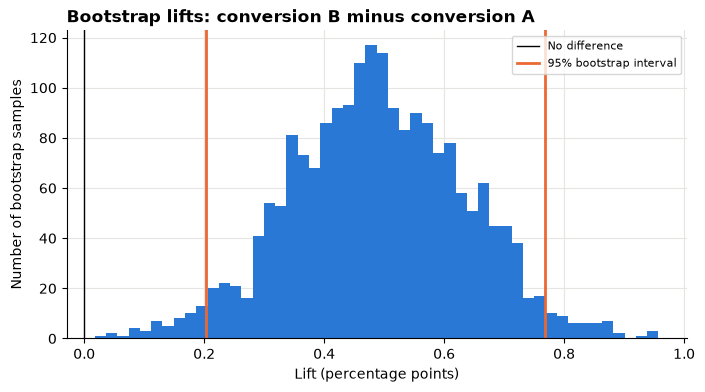

Bootstrap 95% CI for the lift: +0.20 to +0.77 percentage points


In [15]:
conv_a = ab.loc[ab["variant"] == "A", "converted"].to_numpy()
conv_b = ab.loc[ab["variant"] == "B", "converted"].to_numpy()

boot_lifts = np.array([
    rng.choice(conv_b, size=len(conv_b)).mean() - rng.choice(conv_a, size=len(conv_a)).mean()
    for _ in range(2000)
])
lift_low, lift_high = np.percentile(boot_lifts, [2.5, 97.5])

ax = plt.gca()
ax.hist(boot_lifts * 100, bins=50)
ax.axvline(0, color="black", linewidth=1, label="No difference")
ax.axvline(lift_low * 100, color="#eb6834", linewidth=2, label="95% bootstrap interval")
ax.axvline(lift_high * 100, color="#eb6834", linewidth=2)
ax.set_title("Bootstrap lifts: conversion B minus conversion A")
ax.set_xlabel("Lift (percentage points)")
ax.set_ylabel("Number of bootstrap samples")
ax.legend(fontsize=8)
plt.show()
print(f"Bootstrap 95% CI for the lift: {lift_low * 100:+.2f} to {lift_high * 100:+.2f} percentage points")

**Formula:** the SE of a difference between two proportions combines the SE of each group:

*SE = √( rate A × (1 − rate A) ÷ visitors A  +  rate B × (1 − rate B) ÷ visitors B )*, and the interval is *lift ± 1.96 × SE*.

In [16]:
n_a, n_b = len(conv_a), len(conv_b)
se_lift = math.sqrt(rate_a * (1 - rate_a) / n_a + rate_b * (1 - rate_b) / n_b)

pd.DataFrame({
    "low (points)": [lift_low * 100, (lift - 1.96 * se_lift) * 100],
    "high (points)": [lift_high * 100, (lift + 1.96 * se_lift) * 100],
}, index=["Bootstrap", "Formula"]).round(2)

,low (points),high (points)
Bootstrap,0.20,0.77
Formula,0.21,0.79


With tens of thousands of visitors, the bootstrap and the formula agree closely. If the whole interval sits above zero, the data are hard to explain by chance alone; the interval also tells you **how big** the lift plausibly is, from its low end to its high end.

> **Check your understanding 7**
>
> A lift's 95% interval runs from −0.1 to +0.9 percentage points. Can you say B is better? Can you say B makes no difference? What would you tell the manager?

---

## Part 9: A p-value by shuffling (permutation test)

A **p-value** answers one narrow question: *if the new page made **no difference at all**, how often would chance alone produce a gap at least as large as the one we saw?*

We can answer it by simulation. If the page did nothing, the A and B labels are meaningless, so **shuffling** them should not matter. We:

1. Shuffle the variant labels across all visitors (keeping group sizes).
2. Recompute the difference in conversion rates.
3. Repeat thousands of times: this is the "no difference" world.
4. The p-value is the share of shuffles with a gap at least as large (in either direction) as the real one.

> **Predict, then reveal**
>
> In the shuffled world, where will the differences be centred? How many of 5,000 shuffles do you expect to beat the real lift?

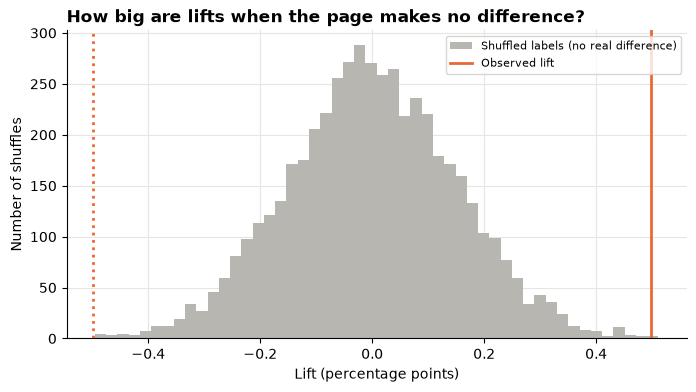

Shuffles with a gap at least as large: 1 of 5000
Permutation p-value: about 0.0002


In [17]:
converted = ab["converted"].to_numpy()
is_b = (ab["variant"] == "B").to_numpy()

shuffled_lifts = np.empty(5000)
for i in range(5000):
    labels = rng.permutation(is_b)
    shuffled_lifts[i] = converted[labels].mean() - converted[~labels].mean()

extreme = (np.abs(shuffled_lifts) >= abs(lift)).sum()

ax = plt.gca()
ax.hist(shuffled_lifts * 100, bins=50, color="#b8b6b0", label="Shuffled labels (no real difference)")
ax.axvline(lift * 100, color="#eb6834", linewidth=2, label="Observed lift")
ax.axvline(-lift * 100, color="#eb6834", linewidth=2, linestyle=":")
ax.set_title("How big are lifts when the page makes no difference?")
ax.set_xlabel("Lift (percentage points)")
ax.set_ylabel("Number of shuffles")
ax.legend(fontsize=8)
plt.show()

print(f"Shuffles with a gap at least as large: {extreme} of 5000")
print(f"Permutation p-value: about {max(extreme, 1) / 5000:.4f}" + (" (an upper bound)" if extreme == 0 else ""))

The grey histogram above is what pure chance produces. The observed lift sits far out in its tail, so very few shuffles (or none) reach it, and the p-value is small.

### The formula shortcut

There is also a formula (the *two-proportion z-test*). It divides the lift by its standard error under the "no difference" assumption and reads the p-value from the bell curve. We wrap it in a function to reuse later; you do not need to memorise it.

In [18]:
def compare_rates(buyers_a, visitors_a, buyers_b, visitors_b):
    """Lift (B - A), its 95% interval and a two-sided p-value, by the normal formula."""
    rate_a, rate_b = buyers_a / visitors_a, buyers_b / visitors_b
    lift = rate_b - rate_a
    se = math.sqrt(rate_a * (1 - rate_a) / visitors_a + rate_b * (1 - rate_b) / visitors_b)
    pooled = (buyers_a + buyers_b) / (visitors_a + visitors_b)          # "no difference" rate
    se_null = math.sqrt(pooled * (1 - pooled) * (1 / visitors_a + 1 / visitors_b))
    z = lift / se_null
    p_value = math.erfc(abs(z) / math.sqrt(2))                           # two-sided, from the bell curve
    return {"lift": lift, "low": lift - 1.96 * se, "high": lift + 1.96 * se, "z": z, "p_value": p_value}


result = compare_rates(conv_a.sum(), n_a, conv_b.sum(), n_b)
print(f"Formula p-value: {result['p_value']:.4f} (z = {result['z']:.2f})")

Formula p-value: 0.0008 (z = 3.37)


Compare the two p-values in the outputs above. They tell the same story: chance is a poor explanation for the gap. When only a handful of shuffles reach the observed gap, the permutation p-value is rough (one more or one fewer extreme shuffle changes it a lot); more shuffles would sharpen it. With large samples like this one, the formula is a good shortcut.

---

## Part 10: Reading a p-value, and practical versus statistical significance

**In plain language:** "If the new page truly made no difference, a gap this large would happen by chance in about *p* of tests." A small p-value (by convention below 0.05) means chance is a poor explanation; we call the result **statistically significant**.

| Common misreading | Why it is wrong |
|---|---|
| "p is the probability that the page has no effect." | p assumes no effect and asks how surprising the data are. It is not the probability of the assumption. |
| "1 − p is the probability that B is better." | Same mistake in reverse. |
| "p < 0.05, so the effect is big and important." | p mixes effect size with sample size. A tiny effect in a huge sample gets a tiny p. |
| "p > 0.05, so there is no difference." | Not significant means **not shown**, not "shown to be zero". Look at the interval. |
| "p = 0.049 is a success and p = 0.051 a failure." | 0.05 is a convention, not a cliff. Report the interval and the p-value. |

**Practical significance** asks whether the effect is big enough to matter for the business. Statistical significance only asks whether chance is a poor explanation. The confidence interval answers both: its position says whether zero is plausible, its ends say how big the effect could be.

> **Predict, then reveal**
>
> Two made-up tests. Test 1 has 5 million visitors per group and a true lift of 0.1 percentage points. Test 2 has 1,000 visitors per group and a true lift of 1 percentage point. Which one will be "statistically significant"? Which one matters more for the business?

In [19]:
sim = np.random.default_rng(seed=21)
tests = {"Test 1": (5_000_000, 0.030, 0.031),     # visitors per group, true rate A, true rate B
         "Test 2": (1_000, 0.030, 0.040)}
rows = {}
for name, (visitors, true_a, true_b) in tests.items():
    buyers_a, buyers_b = sim.binomial(visitors, true_a), sim.binomial(visitors, true_b)
    r = compare_rates(buyers_a, visitors, buyers_b, visitors)
    rows[name] = {"visitors per group": f"{visitors:,}",
                  "lift (points)": f"{r['lift'] * 100:+.2f}",
                  "95% CI (points)": f"{r['low'] * 100:+.2f} to {r['high'] * 100:+.2f}",
                  "p-value": f"{r['p_value']:.4f}" if r["p_value"] >= 0.0001 else "below 0.0001"}
pd.DataFrame(rows).T

,visitors per group,lift (points),95% CI (points),p-value
Test 1,"5,000,000",+0.08,+0.06 to +0.10,below 0.0001
Test 2,"1,000",+0.50,-1.03 to +2.03,0.5221


Read the table above. The huge test is clearly "significant", yet its lift is so small it may not pay for the change. The small test was built with a lift that would matter, but its interval is so wide that it cannot tell a worthwhile lift from zero, or even from a loss. Neither "significant" nor "not significant" is the whole story. **Always report the interval, in the units the manager cares about.**

> **Check your understanding 8**
>
> Translate the checkout-page lift and its interval into "extra buyers per 10,000 visitors". Which number would you put in the headline for a manager, the p-value or this?

---

## Part 11: Peeking and multiple comparisons

A 5% significance threshold means a **false winner 5% of the time when there is no real effect**, but only if you look **once**, at **one** result, decided in advance. Two everyday habits break that promise.

### Peeking

A colleague checks the test every day and stops the first day the p-value dips below 0.05. To see what that does, we make an **A/A test**: we shuffle the variant labels in the real data, so there is no real difference by construction, then follow the running result day by day.

> **Predict, then reveal**
>
> In A/A tests with no real difference, what share would end with a "winner" if you checked only on the last day? And if you checked every day and stopped at the first significant day?

A/A tests with a 'winner' when checked once, on the last day: 5.2%
A/A tests with a 'winner' when checked every day:           27.1%


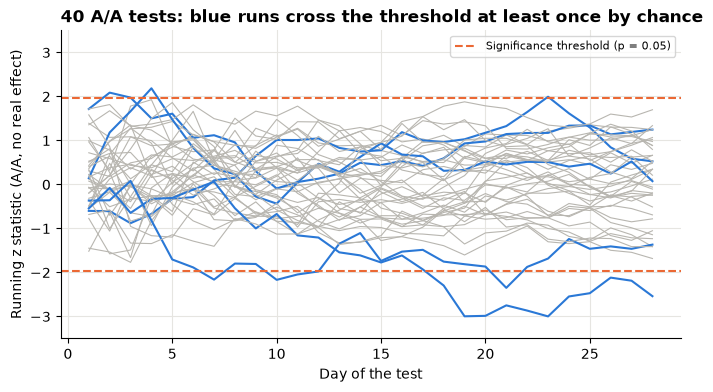

In [20]:
day = (ab["date"] - ab["date"].min()).dt.days.to_numpy()
n_days = day.max() + 1


def daily_z(labels):
    """Running z statistic after each day of the test, for given B labels."""
    buyers_b = np.cumsum(np.bincount(day[labels], weights=converted[labels], minlength=n_days))
    visitors_b = np.cumsum(np.bincount(day[labels], minlength=n_days))
    buyers_a = np.cumsum(np.bincount(day[~labels], weights=converted[~labels], minlength=n_days))
    visitors_a = np.cumsum(np.bincount(day[~labels], minlength=n_days))
    pooled = (buyers_a + buyers_b) / (visitors_a + visitors_b)
    se_null = np.sqrt(pooled * (1 - pooled) * (1 / visitors_a + 1 / visitors_b))
    return (buyers_b / visitors_b - buyers_a / visitors_a) / se_null


aa_runs = np.array([daily_z(rng.permutation(is_b)) for _ in range(1000)])
significant = np.abs(aa_runs) > 1.96            # |z| above 1.96 is the same as p below 0.05

print(f"A/A tests with a 'winner' when checked once, on the last day: {significant[:, -1].mean():.1%}")
print(f"A/A tests with a 'winner' when checked every day:           {significant.any(axis=1).mean():.1%}")

ax = plt.gca()
for run in aa_runs[:40]:
    crosses = (np.abs(run) > 1.96).any()
    ax.plot(range(1, n_days + 1), run, color="#2a78d6" if crosses else "#b8b6b0",
            linewidth=1.5 if crosses else 0.8)
ax.axhline(1.96, color="#eb6834", linestyle="--", label="Significance threshold (p = 0.05)")
ax.axhline(-1.96, color="#eb6834", linestyle="--")
ax.set_ylim(-3.5, 3.5)
ax.set_title("40 A/A tests: blue runs cross the threshold at least once by chance")
ax.set_xlabel("Day of the test")
ax.set_ylabel("Running z statistic (A/A, no real effect)")
ax.legend(fontsize=8)
plt.show()

Read the two shares above. Checked once, A/A tests produce a false winner about 5% of the time, as promised. Checked every day and stopped at the first dip below 0.05, the false-winner rate is several times higher, because a random walk that wanders long enough crosses the line by chance.

### Multiple comparisons

Another colleague slices the test into **20 slices** (2 devices × the first 10 days) and reports any slice where B "wins". Each slice has a 5% false-alarm chance, so with 20 slices a false alarm somewhere is likely: 1 − 0.95²⁰.

In [21]:
slice_mask = day < 10
slice_key = day[slice_mask] * 2 + (ab["device"].to_numpy()[slice_mask] == "mobile")
conv_s = converted[slice_mask]


def slice_z(labels):
    """z statistic in each of the 20 device x day slices, for given B labels."""
    lab = labels[slice_mask]
    vb = np.bincount(slice_key[lab], minlength=20)
    va = np.bincount(slice_key[~lab], minlength=20)
    bb = np.bincount(slice_key[lab], weights=conv_s[lab], minlength=20)
    ba = np.bincount(slice_key[~lab], weights=conv_s[~lab], minlength=20)
    pooled = (ba + bb) / (va + vb)
    se_null = np.sqrt(pooled * (1 - pooled) * (1 / va + 1 / vb))
    return (bb / vb - ba / va) / se_null


aa_slices = np.array([slice_z(rng.permutation(is_b)) for _ in range(1000)])
print(f"Chance of at least one false alarm in 20 slices, by the rule: {1 - 0.95 ** 20:.0%}")
print(f"Chance of at least one 'significant' slice, A/A simulation:   {(np.abs(aa_slices) > 1.96).any(axis=1).mean():.0%}")

Chance of at least one false alarm in 20 slices, by the rule: 64%
Chance of at least one 'significant' slice, A/A simulation:   63%


With no real effect at all, most A/A tests above still contain at least one "significant" slice. A slice that wins is a **lead for a new test**, not a finding.

> **Rules that keep a test honest**
>
> 1. Before the test starts, write down the **one primary measure**, the **sample size or duration**, and the decision rule.
> 2. Look at the result **once**, at the planned end. (There are methods for planned interim looks; they use stricter thresholds.)
> 3. Treat subgroup and slice results as **hypotheses**. Name the few subgroups you care about in advance, and give each one its own interval.
> 4. Report how many comparisons you made, not only the ones that "worked".

> **Check your understanding 9**
>
> A team ran a test for three weeks, looked at 12 measures and found that "time on page" improved with p = 0.03. What would you ask before believing it?

---

## Part 12: Worked case — the checkout-page result for a manager

We pull everything together into one result table for the manager: conversion rate (in %) and revenue per visitor (in currency units) for A and B, the difference B − A, and a 95% bootstrap interval for that difference ("CI low" to "CI high"). Then one printed sentence with the permutation p-value for conversion.

In [22]:
rev_a = ab.loc[ab["variant"] == "A", "revenue"].to_numpy()
rev_b = ab.loc[ab["variant"] == "B", "revenue"].to_numpy()

boot_rpv = np.empty(2000)
for i in range(2000):
    idx_a = rng.integers(0, n_a, n_a)          # resample visitors, keeping each visitor's
    idx_b = rng.integers(0, n_b, n_b)          # conversion and revenue together
    boot_rpv[i] = rev_b[idx_b].mean() - rev_a[idx_a].mean()

summary = pd.DataFrame({
    "A": [rate_a * 100, rev_a.mean()],
    "B": [rate_b * 100, rev_b.mean()],
    "B − A": [lift * 100, rev_b.mean() - rev_a.mean()],
    "CI low": [lift_low * 100, np.percentile(boot_rpv, 2.5)],
    "CI high": [lift_high * 100, np.percentile(boot_rpv, 97.5)],
}, index=["Conversion (%)", "Revenue per visitor"])
display(summary.round(2))

print(
    f"The new checkout page converted {rate_b:.2%} of visitors against {rate_a:.2%} on the current page, "
    f"a lift of {lift * 100:+.2f} percentage points (95% CI {lift_low * 100:+.2f} to {lift_high * 100:+.2f}). "
    f"That is about {lift * 10000:.0f} extra buyers per 10,000 visitors. "
    f"A gap this large would be very unlikely if the page made no difference (permutation p about {max(extreme, 1) / 5000:.4f})."
)

,A,B,B − A,CI low,CI high
Conversion (%),3.15,3.64,0.50,0.20,0.77
Revenue per visitor,3.08,3.49,0.41,0.09,0.74


The new checkout page converted 3.64% of visitors against 3.15% on the current page, a lift of +0.50 percentage points (95% CI +0.20 to +0.77). That is about 50 extra buyers per 10,000 visitors. A gap this large would be very unlikely if the page made no difference (permutation p about 0.0002).


The printed sentence is the evidence a manager needs: what changed, by how much, how sure we are, and in business units. Before recommending a roll-out you would add **cost** (is the lift worth building and maintaining the page?), and note that this is **one** pre-planned measure checked **once** at the end of the test. In the lab you will also look at how the result differs by device, and why that needs care.

---

## Summary

| Question | Tool | Trap to avoid |
|---|---|---|
| How much would a different sample change my number? | Sampling distribution; standard error | Treating a sample statistic as exact |
| How does precision grow with data? | SE = SD ÷ √n | Expecting 2× data to halve the error (it takes 4×) |
| What range is plausible for the true value? | Bootstrap percentile CI; mean ± 1.96 × SE | "95% chance the truth is in this interval"; tiny skewed samples |
| Did the change cause a difference? | Randomised A/B test with a balance check | Comparing self-selected groups |
| How big is the effect? | Absolute and relative lift, with a CI | Mixing percentage points and percent |
| Could chance explain it? | Permutation p-value | Reading p as the probability of no effect |
| Does it matter? | CI in business units, plus cost | Confusing statistical with practical significance |
| Can I trust the "winner"? | One planned look, one primary measure | Peeking, slicing and reporting only the winners |

---

## Quiz

Answer these at the start of the next lecture, which opens the **finance case**: comparing budgets with what was actually spent. You do not need any finance knowledge; use common sense. Write short answers.

1. A team budgeted 10,000 currency units for travel and actually spent 12,000. What is the difference in currency units, and as a percentage of the budget?
2. For a **cost** line, is spending more than budget good news or bad news for the company? What about earning more **revenue** than budgeted?
3. A new project has a budget of 0 but spent 500. Why can you not calculate a percentage difference, and what would you show instead?
4. Line X is 30% over a budget of 1,000. Line Y is 2% over a budget of 500,000. Which one would you look at first, and why?
5. A department spent much less than its budget. Give one reason that is good news and one reason that might be bad news.
6. A budget table has one row per department per month. You join it to a table of individual invoices and then add up the budget column. What could go wrong?

---

## Lab briefing

In the **Lab** you:

1. Draw repeated samples of Superstore orders and watch the sampling distribution form.
2. Bootstrap a 95% confidence interval for average order value and compare it with the formula.
3. Analyse the checkout-page A/B test: balance by device, conversion and revenue per visitor, lift with an interval, and a permutation p-value.
4. Write a manager-ready sentence for a CI and for the A/B result.
5. Stretch: see how the interval narrows as the sample grows.
6. Challenge: show why daily peeking and slicing by device or day produce misleading winners.

Open the [Session 9 lab](09_sampling_and_experiments_lab.md).